# RoadScan — bounded regularized training
One development experiment using original RDD2022 annotations. Train a fresh COCO-pretrained YOLO26s on the existing audited Japan/India/Czech training pool. Select epochs using only the existing in-domain development split. Compare with the saved reference under identical inference settings. China is a previously inspected external development set, not an untouched test. No US or local test annotations are read. A 90% target is aspirational, not a promised result.

This tests a training recipe as a whole, not the causal effect of any single setting. Training is limited to 30 minutes (with an epoch-boundary overrun possible), 40 epochs, and early stopping. A completed batch session releases its GPU; no interactive training session is needed.

## 1. Environment and provenance
Pin the library version, verify the saved reference checksum, and record the protocol before fitting. Starting from COCO weights avoids continuing the previous road-specific optimization history. The reference nevertheless has prior development selection history; this is not a blind model benchmark.

In [1]:
import sys, subprocess, json, hashlib, shutil, time, gc
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.177'], check=True, timeout=240)
import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
from ultralytics import YOLO
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score
from IPython.display import display
OUT = Path('/kaggle/working/recipe_experiment'); OUT.mkdir(exist_ok=True)
SOURCE = Path('/kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo')
AUDIT = Path('/kaggle/input/notebooks/rimasabunasser/09-roadscan-data-diagnosis/diagnosis')
BASE = Path('/kaggle/input/notebooks/rimasabunasser/10-roadscan-freezing-pilot/freeze_pilot')
REFERENCE = BASE / 'model_bundle/best.pt'
CLASSES = ['D00', 'D10', 'D20', 'D40']
expected = json.loads((BASE/'model_bundle/SHA256.json').read_text())['best.pt']
assert hashlib.sha256(REFERENCE.read_bytes()).hexdigest() == expected
assert torch.cuda.is_available(), 'GPU required. Stop here rather than train on CPU.'
protocol = dict(seed=0, imgsz=640, epochs=40, training_hours=0.5, patience=8,
                source_labels='unchanged', epoch_selection='in_domain_dev mAP50-95',
                external_domain='China development only; previously inspected',
                inference=dict(conf=0.001, iou=0.7, max_det=300, rect=False, nms=True, augment=False),
                reference_sha256=expected)
(OUT/'PROTOCOL.json').write_text(json.dumps(protocol, indent=2))
print('GPU:', torch.cuda.get_device_name(0))
print('Protocol recorded; reference checksum verified.')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 523.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4
Protocol recorded; reference checksum verified.


## 2. Reuse the audited split without changing labels
Copy only the audited training images and the two development manifests. Preserve background images and original labels. Assert split disjointness, unique stems, and identical source/destination labels. Report country and class support rather than silently oversampling or deleting backgrounds. The existing split already excludes audited duplicates; no synthetic offline copies are introduced. This is one country-held-out development setting, not a full leave-one-country-out study.

In [2]:
def rebase(path):
    return str(SOURCE / str(path).split('/RoadScan_yolo/', 1)[1])
audit = pd.read_csv(AUDIT/'label_audit.csv')
tables = {'train': audit[audit['split']=='train'].copy()}
for name in ['in_domain_dev', 'china_dev']:
    tables[name] = audit[audit['split']==name].copy()
    saved = pd.read_csv(BASE/(name+'_manifest.csv'))
    assert set(tables[name].path.map(rebase)) == set(saved.path.map(rebase))
assert [len(tables[k]) for k in ['train','in_domain_dev','china_dev']] == [11149,1000,1977]
LOCAL = Path('/kaggle/temp/recipe_data')
support = []
for split, table in tables.items():
    table['path'] = table.path.map(rebase)
    table['label'] = table.label.map(rebase)
    assert table.path.is_unique
    assert table.path.map(lambda p: Path(p).stem).is_unique
    image_dir = LOCAL/split/'images'; image_dir.mkdir(parents=True, exist_ok=True)
    label_dir = LOCAL/split/'labels'; label_dir.mkdir(exist_ok=True)
    def copy_pair(row):
        source_label = Path(row.label)
        target_label = label_dir/source_label.name
        shutil.copy2(row.path, image_dir/Path(row.path).name)
        shutil.copy2(source_label, target_label)
        assert source_label.read_bytes() == target_label.read_bytes()
    with ThreadPoolExecutor(max_workers=8) as executor:
        list(executor.map(copy_pair, table.itertuples()))
    table.to_csv(OUT/(split+'_manifest.csv'), index=False)
    (OUT/(split+'.txt')).write_text('\n'.join(str(image_dir/Path(p).name) for p in table.path))
    for country, group in table.groupby('country'):
        support.append(dict(split=split,country=country,images=len(group),backgrounds=int((group.boxes==0).sum()),
                            **{c:int((group[c]>0).sum()) for c in CLASSES}))
    print('Staged:',split,len(table),flush=True)
for left,right in [('train','in_domain_dev'),('train','china_dev'),('in_domain_dev','china_dev')]:
    assert set(tables[left].path).isdisjoint(set(tables[right].path))
YAMLS = {}
for domain in ['in_domain_dev','china_dev']:
    target = OUT/(domain+'.yaml')
    target.write_text(yaml.safe_dump(dict(path=str(LOCAL),train=str(OUT/'train.txt'),
                    val=str(OUT/(domain+'.txt')),names=dict(enumerate(CLASSES)))))
    YAMLS[domain] = str(target)
support = pd.DataFrame(support); support.to_csv(OUT/'support.csv',index=False); display(support)


Staged: train 11149
Staged: in_domain_dev 1000
Staged: china_dev 1977


,split,country,images,backgrounds,D00,D10,D20,D40
0,train,Czech,1271,788,355,136,44,66
1,train,India,4471,2617,622,34,1011,875
2,train,Japan,5407,1361,1446,1165,2419,714
3,in_domain_dev,Czech,202,133,50,13,10,13
4,in_domain_dev,India,124,67,15,1,36,24
5,in_domain_dev,Japan,674,158,185,139,303,89
6,china_dev,China,1977,43,1419,738,486,164


## 3. Fit one regularized candidate
Use AdamW, cosine decay, warmup, weight decay, online mosaic, mild mixup, and geometric/photometric augmentation. Do not use random erasing: the standard parameter applies to classification. All layers are trainable. Keep the existing country imbalance visible; sampling is not changed in this experiment. Save epoch checkpoints for recovery. The best checkpoint is chosen by in-domain detection mAP50-95; China cannot stop training or select an epoch. Early stopping limits deterioration but does not guarantee absence of overfitting.

In [ ]:
fit_started = time.monotonic()
model = YOLO('yolo26s.pt')
model.train(data=YAMLS['in_domain_dev'], imgsz=640, epochs=40, time=0.5, patience=8,
            batch=16, device=0, workers=2, seed=0, deterministic=True,
            optimizer='AdamW', lr0=1e-3, lrf=0.01, cos_lr=True, warmup_epochs=3,
            weight_decay=5e-4, mosaic=1.0, close_mosaic=10, mixup=0.1,
            scale=0.5, translate=0.1, degrees=5, fliplr=0.5,
            hsv_h=0.02, hsv_s=0.7, hsv_v=0.4, freeze=None,
            cache=False, amp=True, plots=True, save=True, save_period=5,
            project=str(OUT/'runs'), name='regularized', exist_ok=False)
TRAINED = Path(model.trainer.save_dir)/'weights/best.pt'
assert TRAINED.is_file()
training_seconds = time.monotonic()-fit_started
(OUT/'cost.json').write_text(json.dumps(dict(training_seconds=training_seconds),indent=2))
del model; gc.collect(); torch.cuda.empty_cache()
print('Training finished:',round(training_seconds/60,1),'minutes. Best checkpoint:',TRAINED)


New https://pypi.org/project/ultralytics/8.4.180 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/recipe_experiment/in_domain_dev.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model

## 4. Equal detection evaluation and model selection
Evaluate the saved reference and new best checkpoint with exactly the same size, batch size, confidence floor and NMS settings. Select the delivery checkpoint by in-domain mAP50-95 only; show China results regardless of improvement. These reused development scores are not test results. Report each class and country support. Higher training scores alone do not establish better generalization.

In [ ]:
candidates = {'reference': REFERENCE, 'regularized': TRAINED}
rows, class_rows = [], []
for arm, checkpoint in candidates.items():
    for domain in ['in_domain_dev','china_dev']:
        detector = YOLO(str(checkpoint))
        result = detector.val(data=YAMLS[domain],imgsz=640,batch=4,device=0,workers=2,
                              **protocol['inference'],plots=False,
                              project=str(OUT/'evaluation'),name=f'{arm}_{domain}')
        rows.append(dict(arm=arm,domain=domain,mAP50=float(result.box.map50),
                         mAP50_95=float(result.box.map),precision=float(result.box.mp),recall=float(result.box.mr)))
        for i,c in enumerate(result.box.ap_class_index):
            p,r,a50,a=result.box.class_result(i)
            class_rows.append(dict(arm=arm,domain=domain,class_name=CLASSES[int(c)],precision=float(p),recall=float(r),AP50=float(a50),AP50_95=float(a)))
        pd.DataFrame(rows).to_csv(OUT/'domain_results.csv',index=False)
        pd.DataFrame(class_rows).to_csv(OUT/'class_results.csv',index=False)
        del detector,result; gc.collect(); torch.cuda.empty_cache()
results = pd.DataFrame(rows)
selection = results[results.domain=='in_domain_dev'].sort_values('mAP50_95',ascending=False)
WINNER = selection.iloc[0].arm
(OUT/'selection.json').write_text(json.dumps(dict(winner=WINNER,criterion='in_domain_dev mAP50-95 only'),indent=2))
display(results); print('Selected by in-domain validation:',WINNER)


## 5. Image-level metrics with locked thresholds
For each image and class, use the maximum predicted box score (zero if absent). Calibrate each threshold using only in-domain development predictions. Lock those thresholds before evaluating China. Report per-class precision/recall/F1 and AUROC, plus macro-F1; this differs from detection mAP. Retain backgrounds and all images. AP uses the low confidence floor without F1 threshold filtering. An undefined AUROC is reported as missing, not perfect.

In [8]:
import traceback
if getattr(sys, 'last_traceback', None) is not None:
    traceback.clear_frames(sys.last_traceback)
for variable in ['stream', 'detector']:
    globals().pop(variable, None)
gc.collect(); torch.cuda.empty_cache()
detector = YOLO(str(candidates[WINNER]))
image_data = {}
for domain in ['in_domain_dev','china_dev']:
    table = tables[domain].reset_index(drop=True)
    paths = [str(LOCAL/domain/'images'/Path(p).name) for p in table.path]
    scores = np.zeros((len(paths),4),dtype=np.float32)
    truth = np.zeros((len(paths),4),dtype=np.uint8)
    for i,path in enumerate(table.label):
        for line in Path(path).read_text().splitlines():
            if line.strip(): truth[i,int(line.split()[0])] = 1
    count = 0
    for offset in range(0, len(paths), 4):
        predictions = detector.predict(paths[offset:offset+4], stream=False, imgsz=640,
                                       batch=4, device=0, verbose=False, **protocol['inference'])
        for j, prediction in enumerate(predictions):
            for cls,conf in zip(prediction.boxes.cls.cpu().numpy().astype(int), prediction.boxes.conf.cpu().numpy()):
                scores[offset+j,cls] = max(scores[offset+j,cls],float(conf))
            count += 1
        del predictions
    assert count == len(paths)
    np.savez_compressed(OUT/(domain+'_image_predictions.npz'),truth=truth,scores=scores,paths=np.array(paths))
    image_data[domain] = (truth,scores)
thresholds = []
y,p = image_data['in_domain_dev']
for c in range(4):
    grid = np.linspace(0.01,0.99,99)
    f1 = [precision_recall_fscore_support(y[:,c],p[:,c]>=t,average='binary',zero_division=0)[2] for t in grid]
    thresholds.append(float(grid[np.argmax(f1)]))
(OUT/'thresholds.json').write_text(json.dumps(dict(zip(CLASSES,thresholds)),indent=2))
image_rows = []
for domain,(truth,scores) in image_data.items():
    predicted = scores >= np.array(thresholds)
    precision,recall,f1,_ = precision_recall_fscore_support(truth,predicted,zero_division=0)
    for c,name in enumerate(CLASSES):
        auc = float(roc_auc_score(truth[:,c],scores[:,c])) if len(np.unique(truth[:,c]))==2 else None
        image_rows.append(dict(domain=domain,class_name=name,threshold=thresholds[c],precision=precision[c],recall=recall[c],F1=f1[c],AUROC=auc))
image_results = pd.DataFrame(image_rows)
image_results.to_csv(OUT/'image_results.csv',index=False)
display(image_results); display(image_results.groupby('domain')[['F1','AUROC']].mean())
del detector; gc.collect(); torch.cuda.empty_cache()


,domain,class_name,threshold,precision,recall,F1,AUROC
0,in_domain_dev,D00,0.17,0.708000,0.708000,0.708000,0.896621
1,in_domain_dev,D10,0.21,0.647799,0.673203,0.660256,0.921592
2,in_domain_dev,D20,0.17,0.934132,0.893983,0.913616,0.975128
3,in_domain_dev,D40,0.18,0.825688,0.714286,0.765957,0.954769
4,china_dev,D00,0.17,0.966013,0.520789,0.676740,0.898012
5,china_dev,D10,0.21,0.871914,0.765583,0.815296,0.954831
6,china_dev,D20,0.17,0.785068,0.713992,0.747845,0.905070
7,china_dev,D40,0.18,0.394161,0.329268,0.358804,0.832658


,F1,AUROC
domain,,
china_dev,0.649671,0.897643
in_domain_dev,0.761958,0.937027


## 6. Save the deployable checkpoint and an honest report
Package the selected weights, inference script, pinned requirements, configuration and checksums. Plot training and validation curves to reveal divergence. Preserve the candidate even if it loses. These results cannot certify Saudi road performance or a 90% acceptance target. A geographically separated, annotated local test is still required. No tiling, TTA, ensembling, relabeling, or test-set threshold tuning is performed.

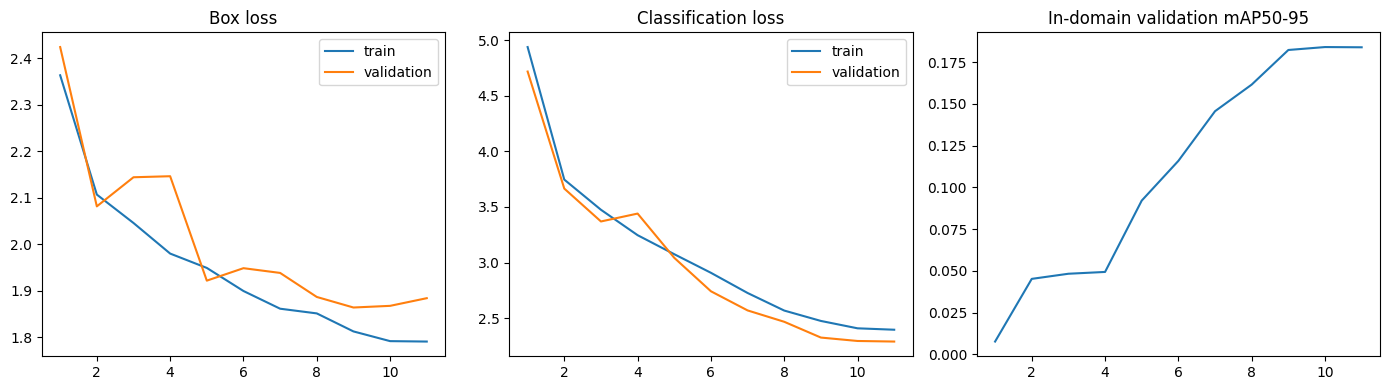

EXPERIMENT COMPLETE. Results, candidate weights and deployable ZIP saved.


In [9]:
history = pd.read_csv(OUT/'runs/regularized/results.csv'); history.columns=history.columns.str.strip()
fig,axes = plt.subplots(1,3,figsize=(14,4))
for ax,train,val,title in [(axes[0],'train/box_loss','val/box_loss','Box loss'),(axes[1],'train/cls_loss','val/cls_loss','Classification loss')]:
    ax.plot(history.epoch,history[train],label='train');ax.plot(history.epoch,history[val],label='validation');ax.set_title(title);ax.legend()
axes[2].plot(history.epoch,history['metrics/mAP50-95(B)']);axes[2].set_title('In-domain validation mAP50-95')
fig.tight_layout();fig.savefig(OUT/'learning_curves.png',dpi=150);plt.show();plt.close(fig)
bundle = OUT/'model_bundle';bundle.mkdir(exist_ok=True)
shutil.copy2(candidates[WINNER],bundle/'best.pt')
config = dict(classes=CLASSES,imgsz=640,display_confidence=0.25,image_thresholds=thresholds,
              iou=0.7,max_det=300,rect=False,nms=True,augment=False,selected_arm=WINNER)
(bundle/'config.json').write_text(json.dumps(config,indent=2))
(bundle/'requirements.txt').write_text('ultralytics==8.4.177\n')
(bundle/'predict.py').write_text("import argparse,json\nfrom pathlib import Path\nfrom ultralytics import YOLO\np=argparse.ArgumentParser()\np.add_argument('--image',required=True)\np.add_argument('--device',default='cpu')\na=p.parse_args()\nr=Path(__file__).resolve().parent\nc=json.loads((r/'config.json').read_text())\nYOLO(str(r/'best.pt')).predict(a.image,device=a.device,imgsz=c['imgsz'],conf=c['display_confidence'],iou=c['iou'],max_det=c['max_det'],rect=False,nms=True,augment=False,save=True)\n")
report = ['# RoadScan regularized development experiment',
          'Selected by in-domain development mAP50-95: '+WINNER,
          'Training minutes: '+str(round(training_seconds/60,2)),
          '## Detection',results.to_markdown(index=False),'## Per class',pd.DataFrame(class_rows).to_markdown(index=False),
          '## Image classification',image_results.to_markdown(index=False),
          '## Limitations','Single seed and a joint recipe change; not a causal augmentation ablation. Reused development data, prior reference selection history, no blind China or Saudi claim. F1 and detection AP measure different tasks. Early stopping does not prove absence of overfitting. Local geographically independent evaluation is pending. Targets of 90–97% are not achieved unless the actual reported metric establishes them. No held-out US/local labels were read.',
          '## Run inference','pip install -r requirements.txt\npython predict.py --image example.jpg']
(OUT/'REPORT.md').write_text('\n\n'.join(report))
(bundle/'MODEL_CARD.md').write_text((OUT/'REPORT.md').read_text())
(bundle/'SHA256.json').write_text(json.dumps({p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in bundle.iterdir() if p.is_file() and p.name!='SHA256.json'},indent=2))
shutil.make_archive('/kaggle/working/roadscan_recipe_model','zip',root_dir=bundle)
print('EXPERIMENT COMPLETE. Results, candidate weights and deployable ZIP saved.')


## 7. Final review and package verification
The 30-minute budget produced 11 logged epochs (about 31 minutes including final validation). The fresh COCO candidate did not beat the saved reference on either development domain, so retain the reference. This does not establish that the recipe is inferior under equal training budgets: the reference had substantially more earlier road training. Time-based scheduling reduced the planned epoch count; close_mosaic=10 disabled mosaic after the first epoch in this run. Image F1 thresholds were selected on in-domain development only; China F1 uses those locked thresholds. AUROC is a ranking metric and must not be presented as accuracy or detection mAP. The image-level results below belong to the selected reference, not the rejected candidate.

The initial batch request was cancelled after remaining queued. Interactive training completed; image evaluation required explicit four-image inference chunks after an out-of-memory error with a whole list. No training was repeated for that repair. Verify checksums, fresh-process CPU loading and report contents before saving outputs and stopping the GPU session.

In [10]:
review = '''

## Final scientific review
11 epochs were logged within the 30-minute fitting budget; training plus final validation took 31.03 minutes. The fresh COCO candidate lost to the saved reference under identical evaluation. This is a bounded development screening experiment, not an equal-total-training-budget comparison. Time-based scheduling changed the epoch count; mosaic closed after epoch one because close_mosaic=10 covered almost the entire shortened run. Image-level metrics and locked thresholds refer to the selected reference. China remains previously inspected development data; no Saudi deployment accuracy is established. AUROC must not be reported as accuracy. The 90% macro-F1 target was not met.
The original batch request was cancelled while queued. Interactive training completed; image-level inference was repaired to explicit chunks of four after a list-input memory error. No road training was repeated.
'''
with (OUT/'REPORT.md').open('a') as file: file.write(review)
(bundle/'MODEL_CARD.md').write_text((OUT/'REPORT.md').read_text())
check = subprocess.run([sys.executable, '-c', "from ultralytics import YOLO; m=YOLO("+repr(str(bundle/'best.pt'))+"); m.predict("+repr(str(LOCAL/'in_domain_dev/images'/Path(tables['in_domain_dev'].iloc[0].path).name))+",device='cpu',imgsz=640,conf=.25,rect=False,nms=True,verbose=False); print('Fresh CPU inference passed')"], capture_output=True,text=True,timeout=120)
(OUT/'fresh_load.txt').write_text(check.stdout+check.stderr)
assert check.returncode == 0, check.stderr
assert hashlib.sha256((bundle/'best.pt').read_bytes()).hexdigest() == expected
(bundle/'SHA256.json').write_text(json.dumps({p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in bundle.iterdir() if p.is_file() and p.name!='SHA256.json'},indent=2))
for name,digest in json.loads((bundle/'SHA256.json').read_text()).items():
    assert hashlib.sha256((bundle/name).read_bytes()).hexdigest()==digest
shutil.make_archive('/kaggle/working/roadscan_recipe_model','zip',root_dir=bundle)
print('Verified: selected reference identity, bundle hashes, fresh CPU inference.')
print('Training minutes:',round(training_seconds/60,2))
display(results)
display(image_results.groupby('domain')[['F1','AUROC']].mean())
print('READY TO SAVE OUTPUTS AND STOP SESSION')

Verified: selected reference identity, bundle hashes, fresh CPU inference.
Training minutes: 31.03


,arm,domain,mAP50,mAP50_95,precision,recall
0,reference,in_domain_dev,0.494317,0.229925,0.594249,0.466486
1,reference,china_dev,0.259186,0.106458,0.340680,0.309798
2,regularized,in_domain_dev,0.396609,0.171135,0.479185,0.441811
3,regularized,china_dev,0.168571,0.058691,0.247935,0.236872


,F1,AUROC
domain,,
china_dev,0.649671,0.897643
in_domain_dev,0.761958,0.937027


READY TO SAVE OUTPUTS AND STOP SESSION
